# Intelligent Vehicles (ME41106) / Machine Perception (RO47004)
* (c) TU Delft, 2021-2026
* Period: 2026-2027, Q2

Make sure you fill in any place that says `YOUR CODE HERE` or `YOUR ANSWER HERE`. Moreover, if you see an empty cell, please DO NOT delete it, instead run that cell as you would run all other cells. Please fill in your name(s) and other required details below:

In [1]:
GROUP_NUMBER = "11"
STUDENT_NAME1 = "Oscar Wells"
STUDENT_NUMBER1 = "6804071"
STUDENT_NAME2 = "Adi"
STUDENT_NUMBER2 = "5"
# fill variables above and remove the NotImplementedError() below
# YOUR CODE HERE


In [2]:
# Note: this block is a check that you have filled in the above information.
# It will throw an AssertionError until all fields are filled
assert GROUP_NUMBER != ""
assert STUDENT_NAME1 != ""
assert STUDENT_NUMBER1 != ""
assert STUDENT_NAME2 != ""
assert STUDENT_NUMBER2 != ""

### General announcements

* AI tools (e.g. ChatGPT, Gemini, Claude) may be used as a tutor: to explain concepts, to debug code you wrote yourself and to get feedback on it. Try first, then use AI to check and extend. AI can make the exercise easier and the learning smaller, and the final exam is without AI.

* You are fully responsible for what you submit. Both group members must understand every line of code and every answer, be able to explain it and stand behind it. A solution you did not conceive and cannot explain is not acceptable, whether it comes from AI or from someone else.

* Academic integrity. It is not permitted to use solution concepts or code from outside your group (this includes AI-generated code beyond the use described above), to share your solution concepts, code or answers with anyone outside your group (also online, e.g. social media or WhatsApp, and also after the deadline), or to distribute the assignment texts, at any time. Suspected cases are forwarded to the Examination Board; penalties include exclusion from the course, inclusion in an academic dishonesty registry, and removal from the MSc program.

* Do not email us your questions directly, since we want to provide everybody with the same information and avoid repeating the same answers. Instead, please post your questions regarding this assignment in the correct support forum on Brightspace, this way everybody can benefit from the response. If you do have a particular question that you want to ask directly, please use the scheduled practicum hours to ask a TA.

* The courses Machine Perception (RO47004) and Intelligent Vehicles (ME41106) share the Practicums 1 and 2. The associated fora will be administered only once, in the Brightspace of the Machine Perception course. Intelligent Vehicles students are requested to enroll the Brightspace of Machine Perception. Practicum 3 and the Final Assignments differ for these courses.

### Groups

* you will be randomly assigned to a group of two, for each of the three Practicums anew.

* Find out the contact details of your lab partner via Brightspace -> Collaboration -> Groups. Contact your lab partner via email and verify that you can communicate with each other.

### Submission guidelines

* The practica are for practice: they are graded PASS/FAIL, and at least 2 of the 3 must be PASS for admittance to the Final Assignment. The written questions help you to reflect and check your own understanding. Their content is not graded, but every written question must be answered for a PASS: no answer cell in the submitted notebook may still contain the placeholder text `YOUR ANSWER HERE`. You can discuss your answers with a TA during the practicum sessions.

* There is a strict deadline for each practicum. Both you and your partner are responsible to ensure that the work is uploaded in time. So, please double check that the upload succeeded to Brightspace and that the correct file is uploaded. If your partner did the upload, then verify on Brightspace that your partner uploaded the file successfully. For Practicum 1-3, late submissions result in a "fail" for that particular practicum.

* Note that only a single submission is required for your group. It is possible to re-submit. Only your last submission is kept by Brightspace. Note that re-submitting after the deadline activates the late-policy!

* Only submit the `*.ipynb` file and nothing else. Note that this means that the `*.py` files should **NOT** be modified. Make sure that your code runs with unaltered `*.py` files before submission.

### Working with Jupyter

* We use nbgrader to manage most cells for automated grading. Nbgrader adds hidden metadata with unique IDs (UUIDs) to each cell. Copying, splitting, or removing a cell will break these IDs and make grading fail. If you need to reuse content, always add a new cell and copy the content instead. To add a cell, switch to command mode by pressing Esc, then press A to insert a cell above or B to insert a cell below.

* This notebook will have in various places a line that throws a `NotImplementedError` exception. These are locations where the assignment requires you to adapt the code. These lines are just there as a reminder for you that you have not yet adapted that particular piece of code, especially when you execute all the cells. Once your solution code replaced these lines, it should accordingly *not* throw any exceptions anymore. Any grading failure due to such reasons would be considered as a failure of that particular section.

* Before you turn this problem in, make sure everything runs as expected. First, **restart the kernel** (in the menubar, select Kernel $\rightarrow$ Restart Kernel…) and then **run all cells** (in the menubar, select Run $\rightarrow$ Run All Cells). Also **clear all outputs** from your cells before submitting (in the menubar, select Edit $\rightarrow$ Clear Outputs of All Cells). Please **save the notebook** file afterwards (Ctrl+s, or File $\rightarrow$ Save Notebook)

---

# Practicum 1

- **Topic:** Features, classification, and detection
- **Deadline:** Friday, 27 November 2026 at 20:00

## Objectives

In this practicum you will study and evaluate feature extraction and pattern classification algorithms that can be used for pedestrian detection from mono RGB images. This practicum will not go very deep in machine learning theory, but is more intended to make you familiar with classification systems and the applications in self-driving vehicles. You will demonstrate that you can create basic classification and localization systems using scikit-learn and PyTorch. Two localization methods will be covered in this practicum: a naive approach employing a sliding window to generate region proposals, and a method that projects 3D priors, such as detections from other sensors, to region proposals in the 2D image plane. You will also evaluate your object detection model using commonly-used metrics for this task. Model design choices - and their effect - are explored throughout the notebook. By the end of this practicum, you will be able to:
- apply Machine Learning methods for feature extraction and classification of pedestrians.
- train a neural network to classify pedestrians using generated features.
- extend a classification model with localization to detect pedestrians in real-world videos.
- use a sliding-window region proposal method for localization.
- project LiDAR detections in 3D space to the 2D image plane.
- evaluate a detection model with commonly used metrics.

<div class="alert alert-info">
Note: The questions asking for written (textual) answers should be answered concisely. None of these questions require lengthy answers in this practicum - you may answer in bullet points, if you prefer. Usually, one or a few sentences suffices.
</div>

<div class="alert alert-warning">
    Warning: Do not use all-UPPERCASE variable names (e.g. <code>TPR</code>, <code>FPR</code>) anywhere in this practicum. This is to prevent violating the Jupyter Notebook naming requirements.
</div>

<div class="alert alert-warning">
Warning: Do not delete any cells in any of the notebooks for the practica. This can break the autograding setup.
</div>

---

## The problem: Pedestrian detection

Our goal is to investigate which features, classifiers, and localization methods give the best result in locating and distinguishing rectangular region proposals as belonging either to the ‘pedestrian’ or ‘non-pedestrian’ class.

The practicum is split into five parts. First, you will explore a number of different **features** that can be extracted from images. Then, **classifiers** are fit on these features to predict whether an image crop contains a pedestrian or not. This is then extended to **detection** with a simple region proposal generation method. An alternative way of generating region proposals is also explored, using **3D priors**. Finally, the **evaluation** of object detectors is covered.

We will use data from the new, real-world View-of-Delft dataset. This dataset consists of short recordings of road scenes made by a vehicle driving through the streets of Delft. This vehicle was equipped with a range of sensors, such as cameras, RADAR, and LiDAR. This practicum will only cover the camera sensors, with later practica exploring the other sensor modalities.

A dataset derived from View-of-Delft is used to fit the feature extractors and classifiers. This datasets consists of tightly-cropped images of pedestrians, as well as crops of arbitrary regions to represent non-pedestrians.  There are 3000 samples (1500 pedestrian and 1500 non-pedestrian) available for training in this curated dataset. For testing, 1000 samples (500 pedestrian and 500 non-pedestrian) are provided.

One of the scenes in the View-of-Delft dataset will be used to evaluate the object detector in the final parts of the practicum.

---

## Part 1 - Features

We start with loading the data. Note that each 96 by 48 pixel sample is loaded as a 1 by 4608 feature vector.

In [3]:
# CELL REF: C1.0a

# some magic to ease iterative implementation
from IPython import get_ipython

ipython = get_ipython()
if ipython:
    ipython.run_line_magic("load_ext", "autoreload")
    ipython.run_line_magic("autoreload", "2")
    ipython.run_line_magic("matplotlib", "inline")

In [4]:
# CELL REF: C1.0b

import numpy as np
from IPython.core.display import HTML
from tqdm.notebook import tqdm
from matplotlib import pyplot as plt
from copy import copy

# Random seed
np.random.seed(42)

# Format for figures
HTML("""
<style>
.output_png {
    display: table-cell;
    text-align: center;
    vertical-align: middle;
}
</style>
""")

# Check if environment is sourced
import os
if 'MP_IV_SOURCED' not in os.environ:
    raise RuntimeError('The MP&IV environment is not active. Start JupyterLab with: pixi run start')

In [5]:
# CELL REF: C1.0c

from load_data import load_data

X_train_intensity, X_test_intensity, y_train, y_test = load_data()

print('training set shape: ', X_train_intensity.shape)
print('test set shape: ', X_test_intensity.shape)

training set shape:  (3000, 4608)
test set shape:  (1000, 4608)


## Exercise 1.1 - Visualizing Pedestrians

Complete the code to visualize five pedestrian and five background samples from the training data. In order to do this, you have to implement the function `intensities_to_image`. Do not modify the function signature of `intensities_to_image`, because it will be reused later on in this practicum. Training samples `0...1499` correspond to pedestrians and samples `1500...2999` to non-pedestrian samples. Similarly, test samples `0...499` correspond to pedestrians and `500...999` to non-pedestrian samples. 

<div class="alert alert-success">
Hint: Use the numpy function `reshape`.
</div>

More info on working with numpy: https://numpy.org/doc/stable/user/quickstart.html. Also make sure that you understand how _references_ and _copies_ work in Python. You will need this knowledge throughout the course. You can find more info here: https://levelup.gitconnected.com/understanding-reference-and-copy-in-python-c681341a0cd8.

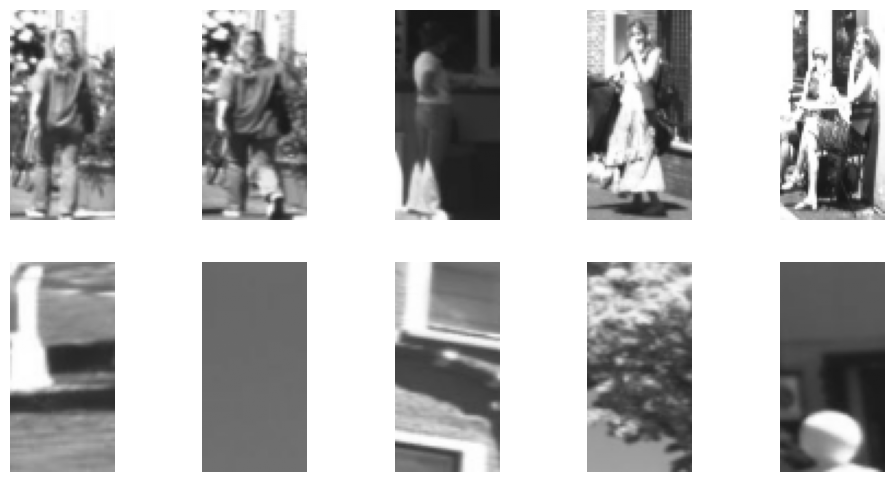

In [6]:
# CELL REF: C1.1a

import numpy as np
import cv2
def intensities_to_image(X):
    # YOUR CODE Here
    image = X.reshape(96,48)   
    return image   # Modify

import matplotlib.pyplot as plt
samples = X_train_intensity[::300,:]
num_of_examples = 10
fig = plt.figure(figsize=(12,6))
for i in range(num_of_examples):
    ax = fig.add_subplot(2, 5, i+1)
    img = intensities_to_image(samples[i,:])
    ax.imshow(img, cmap='gray', vmin=0, vmax=255)
    plt.axis("off")
plt.show()



In [7]:
# CELL REF: C1.1b

assert(intensities_to_image(samples[0,:]).shape == (96, 48))

### Hand-Crafted Features

Classifiers use features to make decisions. Features could be the original pixel intensity values, or derived properties thereof. Feature extraction is the process of calculating these derived properties. A good feature extractor retains those properties that are most descriptive for the classification task, while reducing the total amount of information passed to the classifier. A good feature extractor generalizes the sample in such a way that objects of the same class are similar. This makes the classification task easier.

In the context of pedestrian classification, a good feature extractor would be invariant to - for example - the illumination of the scene, or the color of the clothes of the pedestrian. That means that a feature extractor would ideally be *invariant* to these properties.

Histogram of Oriented Gradients (HOG) is a feature extractor capturing the shape information of the objects by extracting image gradients, since we know that edges and corners contain a lot more information about object shape compared to flat regions.

---

## Exercise 1.2 - HoG Features

Complete the function `calc_feature_length` to calculate the length of a HOG feature vector given the number of orientations (`O`), pixels per cell (`C`), cells per block (`B`), and image size (`W`, `H` for width and height). Assume square cells, a square block shape, a block step of 1 cell (the next block starts 1 cell further, so neighbouring blocks overlap) and that the image size is dividable with the cell size. `C` and `B` are per dimensions, so e.g `B = 2` means 2x2 cells in a Block.

In [8]:
# CELL REF: C1.2a

def calc_feature_length(O, C, B, W, H):
    #cells in in x and y
    cells_x = W // C
    cells_y = H // C
    #blocks in x and y
    blocks_x = cells_x - B + 1
    blocks_y = cells_y - B + 1
    #features per block
    feat_block = B**2 * O
    #feature length
    feature_length = blocks_x * blocks_y * feat_block
    return feature_length
    

O = 8
C = 2
B = 2
W = 48
H = 96

feature_length = calc_feature_length(O, C, B, W, H)
print(f'Feature length: {feature_length}, with O = {O}, C = {C}, B = {B}, W = {W}, H = {H}.')

Feature length: 34592, with O = 8, C = 2, B = 2, W = 48, H = 96.


In [9]:
# CELL REF: C1.2b

assert O == 8
assert C == 2
assert B == 2
assert W == 48
assert H == 96
assert calc_feature_length(O, C, B, W, H) == 34592

Calculate the HOG features of one pedestrian sample and one non-pedestrian sample using [skimage](https://scikit-image.org/docs/dev/auto_examples/features_detection/plot_hog.html). Use the following parameters: 
- number of orientations (`O`) $= 8$
- pixels per cell (`C`) $= 4$
- cells per block (`B`) $= 1$

Plot a visualization of the HOG as an image next to the input samples.

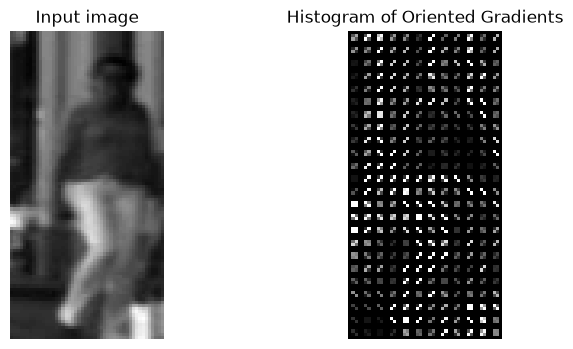

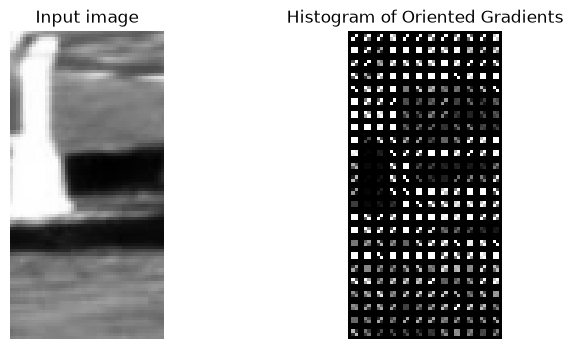

In [10]:
# CELL REF: C1.2c

import matplotlib.pyplot as plt

from skimage.feature import hog
from skimage import data, exposure
O = 8
C = 4
B = 1


image = (intensities_to_image(X_train_intensity[5,:]), intensities_to_image(X_train_intensity[1500,:]))
for k in range (2):
    fd, hog_image = hog(
        image[k],
        orientations=O,
        pixels_per_cell=(C, C),
        cells_per_block=(B, B),
        visualize=True,
    )
    
    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(8, 4), sharex=True, sharey=True)
    
    ax1.axis('off')
    ax1.imshow(image[k], cmap=plt.cm.gray)
    ax1.set_title('Input image')
    
    # Rescale histogram for better display
    hog_image_rescaled = exposure.rescale_intensity(hog_image, in_range=(0, 10))
    
    ax2.axis('off')
    ax2.imshow(hog_image_rescaled, cmap=plt.cm.gray)
    ax2.set_title('Histogram of Oriented Gradients')
    plt.show()

**Q1.2a**: Where are the HoG features the most intense?

## 

At the edges of the object (tbd)

Compute the HOG features for *all* samples of the dataset and store the result in `X_train_hog` and `X_test_hog`. Use the following parameters:
- number of orientations (`O`) $= 8$
- pixels per cell (`C`) $= 4$
- cells per block (`B`) $= 1$

In [11]:
# CELL REF: C1.2d
from skimage.feature import hog
from skimage import data, exposure
X_train_hog = np.zeros((3000, 2304))  # calculate
X_test_hog = np.zeros((1000, 2304))   # calculate
# YOUR CODE HERE
O = 8
C = 4
B = 1

for k in range (len(X_train_intensity)):
    image = intensities_to_image(X_train_intensity[k,:])
    fd, hog_image = hog(
        image,
        orientations=O,
        pixels_per_cell=(C, C),
        cells_per_block=(B, B),
        visualize=True,
    )
    X_train_hog[k] = fd
for k in range (len(X_test_intensity)):
    image = intensities_to_image(X_test_intensity[k,:])
    fd, hog_image = hog(
        image,
        orientations=O,
        pixels_per_cell=(C, C),
        cells_per_block=(B, B),
        visualize=True,
    )
    X_test_hog[k] = fd



In [12]:
# CELL REF: C1.2e

assert(X_train_hog.shape == (3000, 2304))
assert(X_test_hog.shape == (1000, 2304))

### Learnt Features

Features like HOG are "hand-crafted". They are manually engineered with "expert knowledge". The features are then passed to the classification system that can be trained.

The alternative is to *train* a feature extractor to identify and extract useful features for the specific classification task. This is exactly what a Convolutional Neural Network (CNN) does. Training a CNN "from scratch" usually takes a lot of time and requires a lot of annotated data.

The trained weights of a CNN can be reused if the network was trained on a similar task. That is why you are going to use a *pre-trained* network in this practicum. This technique is called *transfer learning*.

Now we will extract features with a pre-trained Convolutional Neural Network (CNN) titled MobileNet with its weights pre-trained on [ImageNet](https://image-net.org/), a large data set of images with many classes that is often used for evaluation of classification systems.

![SegmentLocal](media/MobileNetv2_architecture.svg "MobileNetv2 architecture")
<p style="text-align: center;"><center>
    <sub>
        Image taken from 
        Wang et al., "A New Image Classification Approach via Improved MobileNet Models with Local Receptive Field Expansion in Shallow Layers",
        <i>Computational Intelligence and Neuroscience</i>, 2020,
        <a href="https://doi.org/10.1155/2020/8817849">https://doi.org/10.1155/2020/8817849</a>, 
         on 11 October 2021. 
    </sub>
</center></p>

---

## Exercise 1.3 - CNN Features

First, load the model with the pre-trained weights. We only keep `model.features`, the convolutional part of MobileNetV2. This removes the fully connected classification layers at the end, or 'top', of the network, so that the model acts as a feature extractor for transfer learning. The output of `model.features` is a feature map of shape `(N, 1280, h, w)`. The spatial size `h` × `w` of this map depends on the size of the input images.

In [13]:
# CELL REF: C1.3a

import os
import torch
import torchvision.models as models

# Do not download and cache file from internet, but use file from /data since delftblue does not have internet connection
weights_path = os.path.join(os.environ["PRACTICUM1_DATA_DIR"], "pedestrian_classifier", "mobilenet_v2-7ebf99e0.pth")

# Initialize the MobileNet V2 model architecture
model = models.mobilenet_v2()

# Load the weights from the local file
state_dict = torch.load(weights_path, map_location="cpu")
model.load_state_dict(state_dict)

# Extract the feature extractor part
model = model.features

Calculate the feature vector of the training samples and test samples using MobileNet. Store the features in `X_train_cnn` and `X_test_cnn`.

Preprocess the images before you pass them through MobileNet, in the same way as the ImageNet images that were used to train the weights (see note if interested). Read the [torchvision documentation of MobileNetV2](https://pytorch.org/vision/stable/models/generated/torchvision.models.mobilenet_v2.html) for the required preprocessing. The model expects a `torch.Tensor` of shape `(N, 3, H, W)`: RGB images with the colour channel as the first image axis. You can use the [`skimage`](https://scikit-image.org/docs/stable/api/api.html) module to convert images from grayscale to RGB. Keep the original image size of 96 × 48 pixels: you do not need to resize the images to the ImageNet size of 224 × 224 pixels.

To get one feature vector of length 1280 per sample, average the output feature map over its two spatial dimensions (*global average pooling*, see for example [`torch.nn.functional.adaptive_avg_pool2d`](https://pytorch.org/docs/stable/generated/torch.nn.functional.adaptive_avg_pool2d.html)).

<div class="alert alert-info">
Note: The preprocessing normalizes each colour channel with the mean and standard deviation of the ImageNet training images. This is an example of <a href="https://en.wikipedia.org/wiki/Feature_scaling">feature scaling</a>, a common preprocessing step in machine learning pipelines used to reduce the space of possible inputs and/or improve the convergence of gradient descent.
</div>

In [14]:
# CELL REF: C1.3b

import torch
import skimage


def preprocess_images(X):
    processed_images = []
    # Your solution below. Return 'processed_images' as numpy array.
    # YOUR CODE HERE
    mean = np.array([0.485, 0.456, 0.406])
    std = np.array([0.229, 0.224, 0.225])
    for image in X:
        #reformat
        image = intensities_to_image(image)
        #gray to rgb
        image = skimage.color.gray2rgb(image)
        #rescaled to 0-1
        image = image.astype(np.float32) / 255.0
        #normalised
        image = (image-mean)/std
        # Change dimensions from (H, W, C) to (C, H, W)
        image = np.transpose(image, (2, 0, 1))

        processed_images.append(image)
    processed_images = np.array(processed_images)

    return processed_images


def calculate_cnn(model, X):
    # Your solution below. Return a variable 'conv_feats' (as a numpy array).
    model.eval()
    # YOUR CODE HERE
    # Preprocess images
    images = preprocess_images(X)

    # Convert numpy array to torch tensor
    images = torch.tensor(images, dtype=torch.float32)
    with torch.no_grad():
        conv_feats = model(images)
    
        conv_feats = torch.nn.functional.adaptive_avg_pool2d(conv_feats, (1, 1))
    
        conv_feats = torch.flatten(conv_feats, start_dim=1)
    
    conv_feats = conv_feats.numpy()
    return conv_feats
    
X_train_cnn = calculate_cnn(model, X_train_intensity)
X_test_cnn = calculate_cnn(model, X_test_intensity)


In [15]:
# CELL REF: C1.3c

assert(X_train_cnn.shape == (3000,1280))
assert(X_test_cnn.shape == (1000,1280))

## Part 2 - Classification

### Support Vector Machine classifier

You've now got three feature types of the pedestrian data set:
- Intensity / `X_train_intensity` and `X_test_intensity`
- HOG / `X_train_hog` and `X_test_hog`
- MobileNet / `X_train_cnn` and `X_test_cnn`.

The corresponding labels are `y_train` and `y_test`.

--- 

## Exercise 2.1 - SVM Classifier

Let's train a Support Vector Machine (SVM) for classification on the intensity features in `svm_intensity`.

Use the [SVM implementation of sklearn](https://scikit-learn.org/stable/modules/svm.html). Use a value of `C=2` and a `linear` kernel. Use `random_state=1` (for reproducible output). Use the intensity features as they are, without scaling: the test below checks the number of support vectors, and scaling changes it.

In [16]:
# CELL REF: C2.1a

from sklearn.svm import SVC

print('Fitting the SVM on intensity features - this may take a while.')
svm_intensity = None  # define and fit
# YOUR CODE HERE
svm_intensity = SVC(C = 2,kernel = 'linear',random_state = 1)
svm_intensity.fit(X_train_intensity,y_train)


Fitting the SVM on intensity features - this may take a while.


,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",2
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'linear'
,"random_state random_state: int, RandomState instance or None, default=NoneControls the pseudo random number generation for shuffling the data forprobability estimates. Ignored when `probability` is False.Pass an int for reproducible output across multiple function calls.See :term:`Glossary <random_state>`.",1
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None


In [17]:
# CELL REF: C2.1b

assert(svm_intensity.fit_status_ == 0)
assert(svm_intensity.support_vectors_.shape == (1255, 4608)), svm_intensity.support_vectors_.shape

## Exercise 2.2 - Classification Metrics

Evaluate the performance of the SVM classifier with confusion plots generated from [confusion matrices](https://en.wikipedia.org/wiki/Confusion_matrix). This means that you will need to generate a confusion matrix from the predictions and labels first, then plot this. Although there is an sklearn function for creating the confusion matrix, you will need to implement your own function for this purpose. Use the rows for the true labels and the columns for the predicted labels, with index 0 for non-pedestrian (`False`) and index 1 for pedestrian (`True`). The given function `plot_confusion_matrix` expects this layout. Do not use the sklearn implementation to plot the confusion matrices either (i.e. their [ConfusionMatrixDisplay](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.ConfusionMatrixDisplay.html) class). You will reuse your own functions for a different classifier later on.

<div class="alert alert-info">
Note: the sklearn plotting method <a href="https://scikit-learn.org/stable/modules/generated/sklearn.metrics.ConfusionMatrixDisplay.html#sklearn.metrics.ConfusionMatrixDisplay.from_estimator"><code>ConfusionMatrixDisplay.from_estimator</code></a> is a <a href="https://en.wikipedia.org/wiki/Convenience_function">convenience function</a>. The sklearn implementation generates the predictions from the features and classifier, then creates the confusion matrix using the labels, then plots it. This makes it easy to perform these specific steps when required. <a href="https://github.com/scikit-learn/scikit-learn/blob/main/sklearn/metrics/_plot/confusion_matrix.py">Under the hood</a>, this function is composed of other functions that perform the individual steps. It is good practice to separate low-level procedures like this into functions that are each <a href="https://en.wikipedia.org/wiki/Single-responsibility_principle">responsible for only one thing</a>, and combine these in functions with a higher level of <a href="https://en.wikipedia.org/wiki/Abstraction_principle_(computer_programming)">abstraction</a> for ease of use. See also the <a href="https://en.wikipedia.org/wiki/Unix_philosophy">Unix philosophy</a>.

</div>

In [18]:
# CELL REF: C2.2a

import itertools

def confusion_matrix(y_true, y_pred):
    assert y_true.shape == y_pred.shape
    cm = np.zeros((2,2))   # calculate
    # YOUR CODE HERE
    for k in range(len(y_true)):
        if y_true[k]>0 and y_pred[k]>0:
            cm[1,1] += 1
        elif y_true[k]>0 and y_pred[k]<=0:
            cm[1,0] += 1
        elif y_true[k]<=0 and y_pred[k]>0:
            cm[0,1] += 1
        else:
            cm[0,0] += 1
        
    assert cm.shape == (2,2)
    return cm

def plot_confusion_matrix(cm, classes=['False', 'True'], normalize=False, title='Normalized confusion matrix', cmap=plt.cm.Blues):
    if normalize:
        cm = cm.astype('float') / cm.sum(axis=1)[:, np.newaxis]
    
    plt.imshow(cm, interpolation='nearest', cmap=cmap)

    tick_marks = np.arange(len(classes))
    plt.xticks(tick_marks, classes)
    plt.yticks(tick_marks, classes)    
    fmt = '.2f' if normalize else '.0f'
    thresh = np.sum(cm) / 4.
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        plt.text(j, i, format(cm[i, j], fmt), horizontalalignment="center", color="white" if cm[i, j] > thresh else "black")
    
    plt.title(title)
    plt.colorbar()
    plt.tight_layout()
    plt.ylabel('True label')
    plt.xlabel('Predicted label')

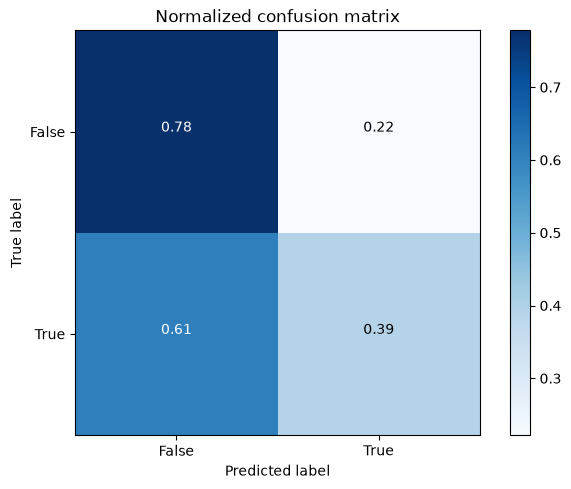

In [19]:
# CELL REF: C2.2b

# predict() returns class labels (0 or 1), not scores, so no threshold is needed.
intensity_preds = svm_intensity.predict(X_test_intensity)
cm = confusion_matrix(y_test, intensity_preds)
plot_confusion_matrix(cm, normalize=True)
plt.show()

Several commonly used metrics for comparing classifiers can be computed from the confusion matrix. A few of these are discussed here.

The true positive rate (TPR) - sometimes called *sensitivity* - is the number of true positives (TP) out of the number of real positive cases (P) in the data.

$TPR = \frac{TP}{P}$

The false positive rate (FPR) - sometimes called *fall-out* - is the number of false positives out of the number of real negative cases (N) in the data.

$FPR = \frac{FP}{N}$

The *accuracy* (A) is the number of true positives and true negatives out of the total number of samples.

$A = \frac{TP+TN}{N+P}$

Calculate the `tpr`, `fpr` and accuracy `accuracy` from the confusion matrix `cm` (not from the rounded numbers in the plot).

In [20]:
# CELL REF: C2.2c

tpr = 0.       # calculate
fpr = 0.       # calculate
accuracy = 0.  # calculate
# YOUR CODE HERE
tpr = cm[1,1]/(cm[1,1]+cm[1,0])
fpr = cm[0,1]/(cm[0,0]+cm[0,1])
accuracy = (cm[1,1] + cm[0,1])/(cm[1,1] + cm[1,0] + cm[0,0] + cm[0,1])

print('TPR/Sensitivity: ', tpr)
print('FPR/Fall-out: ', fpr)
print('Accuracy: ', accuracy)

TPR/Sensitivity:  0.392
FPR/Fall-out:  0.222
Accuracy:  0.307


In [21]:
# CELL REF: C2.2d

assert isinstance(tpr, float)
assert isinstance(fpr, float)
assert isinstance(accuracy, float)
assert(tpr <= 1)
assert(tpr >= 0)
assert(fpr <= 1)
assert(fpr >= 0)
assert(accuracy <= 1)
assert(accuracy >= 0)

The confusion matrix may be different if we change the discrimination threshold. Hence a single confusion matrix does not provide insight in the performance of the classification system at various thresholds. We can plot confusion matrices for multiple thresholds (try it below), but it remains difficult to get an overview of the performance of the classifier with this method.

In [22]:
# CELL REF: C2.2e

from activation_fns import sigmoid

intensity_preds_dist = svm_intensity.decision_function(X_test_intensity)
intensity_preds_prob = sigmoid(intensity_preds_dist)

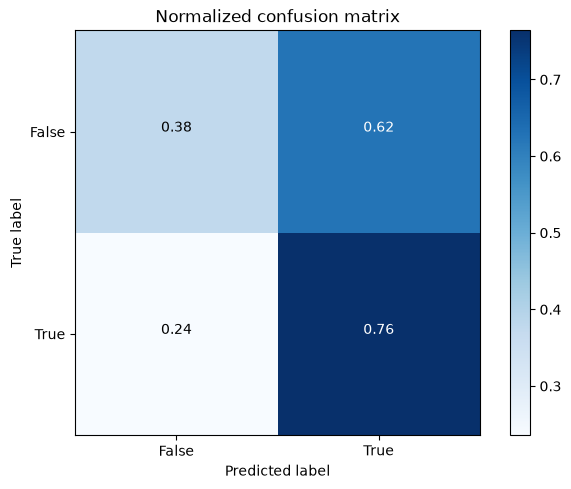

In [23]:
# CELL REF: C2.2f

from evaluation import threshold_predictions

def threshold_and_plot_preds(intensity_preds_prob, threshold):
    intensity_preds_thresh = threshold_predictions(intensity_preds_prob, threshold=threshold)

    plt.clf()
    cm = confusion_matrix(y_test, intensity_preds_thresh)
    plot_confusion_matrix(cm, normalize=True)
    plt.show()

threshold = 0.1
threshold_and_plot_preds(intensity_preds_prob, threshold)

**Q2.2a**: What do you observe when the threshold is at the boundaries of its domain? Why does this happen?

YOUR ANSWER HERE

A receiver operating characteristic (ROC), or simply ROC curve, is a graphical plot which illustrates the performance of a binary classifier system as its discrimination threshold is varied. It is created by plotting the fraction of true positives out of the positives (TPR = true positive rate) vs. the fraction of false positives out of the negatives (FPR = false positive rate), at various threshold settings. TPR is also known as sensitivity, and FPR is one minus the specificity or true negative rate.<sup>[1](https://scikit-learn.org/stable/modules/model_evaluation.html#roc-metrics)</sup>

Plot the ROC curve using sklearn. Do not use their plotting class (i.e. [RocCurveDisplay](https://scikit-learn.org/stable/modules/generated/sklearn.metrics.RocCurveDisplay.html)), for the same reason as before.

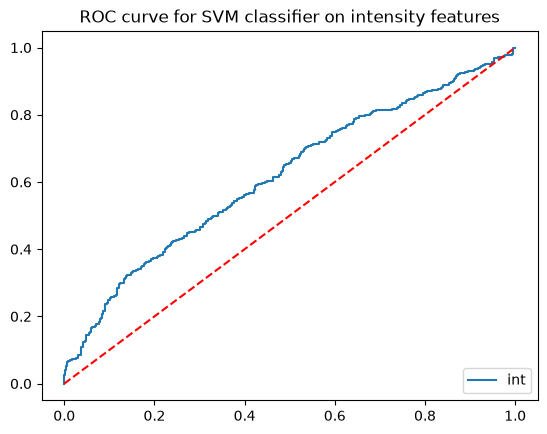

In [24]:
# CELL REF: C2.2g

# YOUR CODE HERE
from sklearn.metrics import roc_curve

# Get prediction scores from the SVM
y_scores = svm_intensity.decision_function(X_test_intensity)

# Calculate false positive rate and true positive rate
fpr, tpr, thresholds = roc_curve(y_test, y_scores)

# Plot ROC curve
plt.plot(fpr, tpr, label="int")

plt.plot([0, 1], [0, 1],'r--')
plt.title('ROC curve for SVM classifier on intensity features')
plt.legend(["int"], loc='lower right')
plt.show()

**Q2.2b**: Give an interpretation of a model with a ROC curve along the red dotted line.

YOUR ANSWER HERE

Train the SVM with the HOG and MobileNet features as well and plot the ROC curves of all three feature types in a single figure. Plot the curves in the order intensity, HOG, MobileNet: the legend in the cell below uses this order.

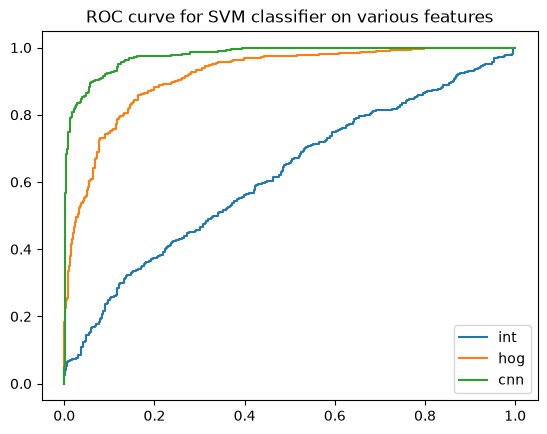

In [25]:
# CELL REF: C2.2h

# YOUR CODE HERE
# Train SVM using HOG features
svm_hog = SVC(C=2, kernel='linear', random_state=1)
svm_hog.fit(X_train_hog, y_train)

# Train SVM using MobileNet features
svm_cnn = SVC(C=2, kernel='linear', random_state=1)
svm_cnn.fit(X_train_cnn, y_train)


# Calculate decision scores for each classifier
y_scores_int = svm_intensity.decision_function(X_test_intensity)
y_scores_hog = svm_hog.decision_function(X_test_hog)
y_scores_cnn = svm_cnn.decision_function(X_test_cnn)


# Calculate ROC values
fpr_int, tpr_int, _ = roc_curve(y_test, y_scores_int)
fpr_hog, tpr_hog, _ = roc_curve(y_test, y_scores_hog)
fpr_cnn, tpr_cnn, _ = roc_curve(y_test, y_scores_cnn)


# Plot all three ROC curves
plt.plot(fpr_int, tpr_int)
plt.plot(fpr_hog, tpr_hog)
plt.plot(fpr_cnn, tpr_cnn)

plt.title('ROC curve for SVM classifier on various features')
plt.legend(["int", "hog", "cnn"], loc='lower right')
plt.show()

**Q2.2c**: Is it possible to rank the performance of the classifier on these feature types from the ROC plot? If so, rank them.

YOUR ANSWER HERE

### Neural classifier

A Support Vector Machine is a type of classifier. Specifically, it is a *linear* classifier because it draws the maximum-margin hyperplane in a feature space to separate the data points of each class. This means that it performs best on a feature space where the data for the classes is separable by a linear decision boundary. However, none of the feature representations used in this practicum are necessarily [linearly separable](https://en.wikipedia.org/wiki/Linear_separability).

You have seen that neural networks can be used to extract useful features from images of pedestrians. However, they can also be used as classifiers; in Deep Learning literature networks used for this purpose are called 'prediction heads' (or simply 'heads'). Due to their parametric nature, neural networks can theoretically learn the optimal (non-linear) decision boundary for a given set of data. This makes them an attractive candidate for challenging classification tasks, and is a reason for their popularity over SVMs.

In this section, you will train a neural network prediction head to classify pedestrians from the MobileNet features. Since these features are already useful for classifying pedestrians, we can afford to use a simple neural network for this task, making it feasible to train in a short period of time!

A figure of the architecture we will use is shown below. The figure shows the input, hidden, and output layers, together with the number of neural 'units' in each layer. The input to the network is the feature representation - the output of MobileNet in our case. The layers are fully-connected, with a ReLU activation after the hidden layer and a sigmoid activation after the output layer.

![SegmentLocal](media/MLP_classifier.drawio.svg "MLP classifier")

The sigmoid ensures that we get an output value in the range $[0,1]$ corresponding to the confidence the classifier has in the features representing a pedestrian. Hence, if the classifier is certain that the input is not a pedestrian, it will output a value of $0$; conversely, an output of $1$ shows that the classifier is certain that the input is a pedestrian. A value between these extremes indicates that the classifier has some uncertainty about the class of the input.

In the PyTorch implementation (`NeuralNetClassifier`), the `forward` method returns the output of the last layer *before* the sigmoid. These raw scores are called *logits* and have a range of $(-\infty, \infty)$. Take this into account when you choose the loss function, and when you convert the network outputs to confidences. During training, the network also applies [dropout](https://pytorch.org/docs/stable/generated/torch.nn.Dropout.html) after the hidden layer.


<div class="alert alert-info">
Note: it is possible to extend SVMs to classification problems on non-linear feature spaces by using the <a href="https://en.wikipedia.org/wiki/Kernel_method">kernel trick</a>. However, this is beyond the scope of this course.
</div>

## Exercise 2.3 - Neural Network Classifier

The cell below shows how to train a neural network from scratch using PyTorch. Select an optimizer from torch.optim (and choose an appropriate learning rate), and pick a suitable loss function from torch.nn. After choosing these components, run the cell to start the training process.

In [26]:
# CELL REF: C2.3a

import torch
import torch.nn as nn
import torch.optim as optim
from NeuralNetClassifier import NeuralNetClassifier

nnc = NeuralNetClassifier()

optimizer = None
loss_fn = None
# YOUR CODE HERE
optimizer = optim.Adam(nnc.parameters(), lr=0.0001)
loss_fn = nn.BCEWithLogitsLoss()

history = nnc.fit(x=X_train_cnn, y=y_train, batch_size=32, epochs=40, verbose=2, optimizer=optimizer, loss_fn=loss_fn)


Epoch 1/40 - loss: 0.4253 - acc: 0.9097
Epoch 2/40 - loss: 0.1839 - acc: 0.9613
Epoch 3/40 - loss: 0.1237 - acc: 0.9710
Epoch 4/40 - loss: 0.0986 - acc: 0.9777
Epoch 5/40 - loss: 0.0782 - acc: 0.9830
Epoch 6/40 - loss: 0.0691 - acc: 0.9830
Epoch 7/40 - loss: 0.0597 - acc: 0.9853
Epoch 8/40 - loss: 0.0567 - acc: 0.9873
Epoch 9/40 - loss: 0.0491 - acc: 0.9867
Epoch 10/40 - loss: 0.0450 - acc: 0.9900
Epoch 11/40 - loss: 0.0395 - acc: 0.9913
Epoch 12/40 - loss: 0.0378 - acc: 0.9917
Epoch 13/40 - loss: 0.0346 - acc: 0.9927
Epoch 14/40 - loss: 0.0299 - acc: 0.9927
Epoch 15/40 - loss: 0.0292 - acc: 0.9943
Epoch 16/40 - loss: 0.0266 - acc: 0.9943
Epoch 17/40 - loss: 0.0249 - acc: 0.9953
Epoch 18/40 - loss: 0.0230 - acc: 0.9950
Epoch 19/40 - loss: 0.0232 - acc: 0.9960
Epoch 20/40 - loss: 0.0197 - acc: 0.9967
Epoch 21/40 - loss: 0.0197 - acc: 0.9967
Epoch 22/40 - loss: 0.0183 - acc: 0.9967
Epoch 23/40 - loss: 0.0167 - acc: 0.9970
Epoch 24/40 - loss: 0.0160 - acc: 0.9983
Epoch 25/40 - loss: 0.014

Generate predictions on the train and test data using the trained neural network classifier. First switch the model to evaluation mode with `nnc.eval()`, so that dropout is disabled. Pass the features as a `torch.Tensor` on the device of the model (`nnc.device`). Run the model inside a [`torch.no_grad()`](https://pytorch.org/docs/stable/generated/torch.no_grad.html) block, so that PyTorch does not store intermediate results for gradient computation. Plot the normalized confusion matrix for both the train and test predictions. Be aware that the neural network classifier outputs logits (see above). Apply the sigmoid function (`torch.sigmoid`) to convert them to the probability of the image containing a pedestrian, with a range of $[0,1]$. Use a confidence threshold of $0.5$ on these probabilities to obtain predicted labels (which you can use to create the confusion matrix).

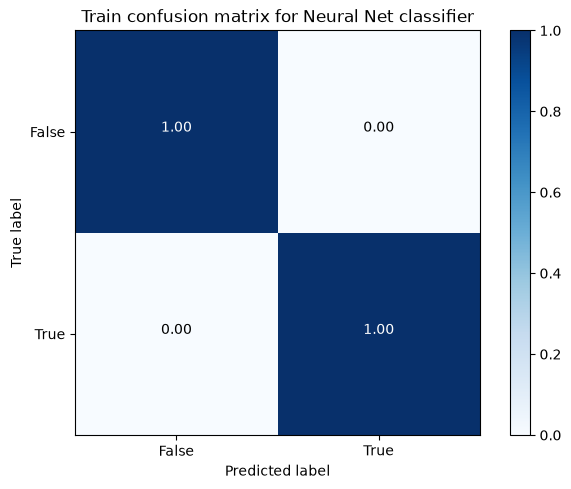

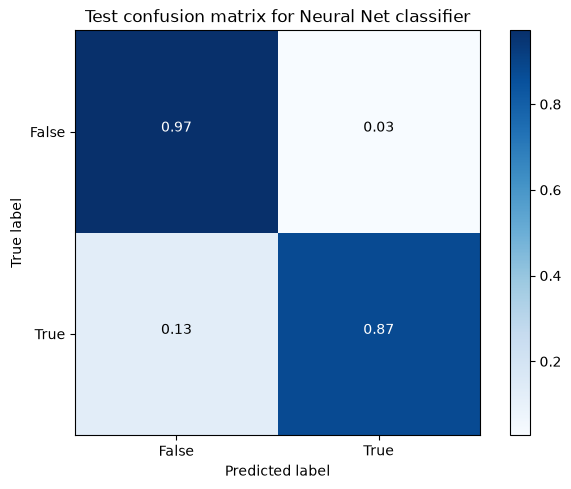

In [27]:
# CELL REF: C2.3b

nn_cm_train = None  # calculate
nn_cm_test = None   # calculate
# YOUR CODE HERE
nnc.eval()

# Convert features to tensors on the model's device
X_train_tensor = torch.tensor(X_train_cnn, dtype=torch.float32).to(nnc.device)
X_test_tensor = torch.tensor(X_test_cnn, dtype=torch.float32).to(nnc.device)

with torch.no_grad():
    # Generate logits
    train_logits = nnc(X_train_tensor)
    test_logits = nnc(X_test_tensor)

    # Convert logits to probabilities
    train_probs = torch.sigmoid(train_logits)
    test_probs = torch.sigmoid(test_logits)

    # Convert probabilities to predicted labels using threshold 0.5
    y_train_pred = (train_probs >= 0.5).int().cpu().numpy().flatten()
    y_test_pred = (test_probs >= 0.5).int().cpu().numpy().flatten()

# Calculate confusion matrices
nn_cm_train = confusion_matrix(y_train, y_train_pred)
nn_cm_test = confusion_matrix(y_test, y_test_pred)

plot_confusion_matrix(nn_cm_train, normalize=True, title='Train confusion matrix for Neural Net classifier')
plt.show()

plot_confusion_matrix(nn_cm_test, normalize=True, title='Test confusion matrix for Neural Net classifier')
plt.show()


**Q2.3a**: Do you notice a difference between the confusion matrices for the train and test data? If so, what could be the reason behind this difference?

YOUR ANSWER HERE

Plot the ROC curves for the neural network classifier and the SVM classifier on the CNN feature representation of the test data. Plot the neural network curve first: the legend in the cell below uses the order `nn_cnn`, `svm_cnn`. Select appropriate limits for your graph (i.e. show the most relevant section of the curves).

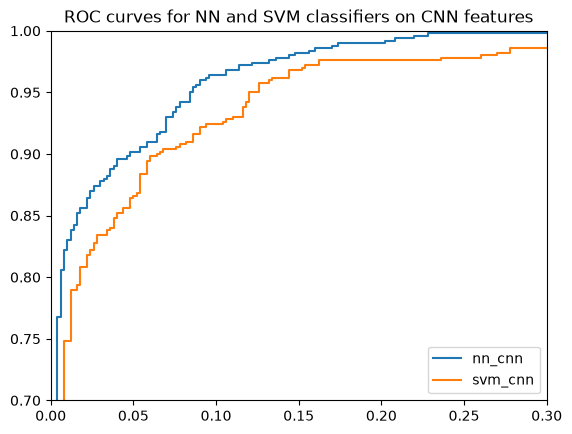

In [28]:
# CELL REF: C2.3c

# YOUR CODE HERE
# Neural network scores (probabilities)
nn_scores = train_probs = None

with torch.no_grad():
    nn_logits = nnc(X_test_tensor)
    nn_scores = torch.sigmoid(nn_logits).cpu().numpy().flatten()

# SVM scores (decision values)
svm_scores = svm_cnn.decision_function(X_test_cnn)

# Calculate ROC curves
fpr_nn, tpr_nn, _ = roc_curve(y_test, nn_scores)
fpr_svm, tpr_svm, _ = roc_curve(y_test, svm_scores)

# Plot neural network first, then SVM
plt.plot(fpr_nn, tpr_nn)
plt.plot(fpr_svm, tpr_svm)

# Random classifier reference
plt.plot([0, 1], [0, 1], 'r--')

# Focus on the most relevant section
plt.xlim(0, 0.3)
plt.ylim(0.7, 1.0)

plt.title('ROC curves for NN and SVM classifiers on CNN features')
plt.legend(['nn_cnn', 'svm_cnn'], loc='lower right')
plt.show()

**Q2.3b**: Which classifier performs better on this feature representation? How does this graph show that? Provide a hypothesis supporting your answer.

YOUR ANSWER HERE

### Pre-trained classifier

We will use a pre-trained model to perform object detection. This model consists of two components: a MobileNet feature extractor and a neural network classification head. The classification head has the same architecture as the neural network (`NeuralNetClassifier`) that you trained earlier, but it uses all 7680 values of the MobileNet feature map instead of the 1280 averaged values. This saves you time in training and will allow you to use a classifier good enough for the challenging object detection task of Section 3!

<img width="100%" alt="Features and classifier relation" src="media/animation_for_features_and_classifier.gif"> 
</img>

The pre-trained model `patch_classifier` is a subclass of `torch.nn.Module`. Like `NeuralNetClassifier`, its `forward` method returns logits. Its `predict` method takes preprocessed images (a numpy array of shape `(N, 3, 96, 48)`) and returns probabilities.

In [29]:
# CELL REF: C2.3d

import skimage.color
import os
import torch
import torch.nn as nn
from torchvision.models import mobilenet_v2, MobileNet_V2_Weights
from practicum1.NeuralNetClassifier import NeuralNetClassifier


def preprocess_images_patch_classifier(X):
    """
    X: (N, 4608) intensity vectors (96*48)
    Returns: (N, 3, 96, 48) RGB, normalized with ImageNet stats
    """
    processed_images = []
    mean = np.array([0.485, 0.456, 0.406], dtype=np.float32)
    std  = np.array([0.229, 0.224, 0.225], dtype=np.float32)

    for x in X:
        # 1) intensity vector -> (96, 48) grayscale
        img_gray = intensities_to_image(x)          # uses your existing C1.1a function

        # 2) gray -> RGB
        rgb = skimage.color.gray2rgb(img_gray).astype(np.float32)

        # 3) scale to [0,1] if needed
        if rgb.max() > 1.0:
            rgb = rgb / 255.0

        # 4) normalize with ImageNet stats
        rgb = (rgb - mean) / std

        # 5) HWC -> CHW
        chw = np.transpose(rgb, (2, 0, 1))          # (3, 96, 48)
        processed_images.append(chw)

    processed_images = np.stack(processed_images, axis=0)  # (N, 3, 96, 48)
    return processed_images

class ImagePatchClassifier(nn.Module):
    """
    Pedestrian patch classifier:
    - feature_model: MobileNetV2 (pretrained)
    - head: NeuralNetClassifier operating on flattened conv features
    """

    def __init__(self, feature_model: nn.Module, head: NeuralNetClassifier):
        super().__init__()
        self.feature_model = feature_model
        self.head = head

    def forward(self, x: torch.Tensor) -> torch.Tensor:
        """
        x: (N, 3, H, W)
        returns: logits (N, 1)
        """
        feats = self.feature_model.features(x)      # (N, C, h, w)
        feats = torch.flatten(feats, start_dim=1)   # (N, D)
        logits = self.head(feats)                   # (N, 1), raw logits
        return logits

    def predict(self, X_proc: np.ndarray, device: torch.device | None = None) -> np.ndarray:
        """
        X_proc: (N, 3, H, W) numpy, already preprocessed (preprocess_images_patch_classifier)
        returns: probabilities (N,) as numpy
        """
        if device is None:
            device = next(self.parameters()).device

        self.eval()
        with torch.no_grad():
            x = torch.from_numpy(X_proc).float().to(device)  # (N, 3, H, W)
            logits = self(x)
            probs = torch.sigmoid(logits).squeeze(1).cpu().numpy()
        return probs

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Rebuild the same architecture as in the training script
feature_model = mobilenet_v2(weights=None)
local_weights_path = os.path.join(os.environ["PRACTICUM1_DATA_DIR"], "pedestrian_classifier", "mobilenet_v2-7ebf99e0.pth")
feature_model.load_state_dict(torch.load(local_weights_path, map_location=device))
head = NeuralNetClassifier(student_version=False)

patch_classifier = ImagePatchClassifier(feature_model, head).to(device)

# Load the trained weights
ckpt_path = os.path.join(
    os.environ["PRACTICUM1_DATA_DIR"],
    "pedestrian_classifier",
    "pedestrian_classifier.pt",
)
state_dict = torch.load(ckpt_path, map_location=device)
patch_classifier.load_state_dict(state_dict)
patch_classifier.eval()

print(patch_classifier)


ImagePatchClassifier(
  (feature_model): MobileNetV2(
    (features): Sequential(
      (0): Conv2dNormActivation(
        (0): Conv2d(3, 32, kernel_size=(3, 3), stride=(2, 2), padding=(1, 1), bias=False)
        (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        (2): ReLU6(inplace=True)
      )
      (1): InvertedResidual(
        (conv): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1), groups=32, bias=False)
            (1): BatchNorm2d(32, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
            (2): ReLU6(inplace=True)
          )
          (1): Conv2d(32, 16, kernel_size=(1, 1), stride=(1, 1), bias=False)
          (2): BatchNorm2d(16, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
        )
      )
      (2): InvertedResidual(
        (conv): Sequential(
          (0): Conv2dNormActivation(
            (0): Conv2d(16, 96,

## Exercise 2.4 - Classifier accuracy

Calculate the `tpr`, `fpr` and accuracy `accuracy` of this classifier on the classification test set, at a confidence threshold value of $0.5$. Plot the confusion matrix.

Remember that the `patch_classifier` consists of both the feature extractor and classifier, which means that you will need to preprocess the inputs for MobileNet (like in Part 1 of the practicum). Use `preprocess_images_patch_classifier` from the cell above for this. Then use `patch_classifier.predict`, which returns probabilities.

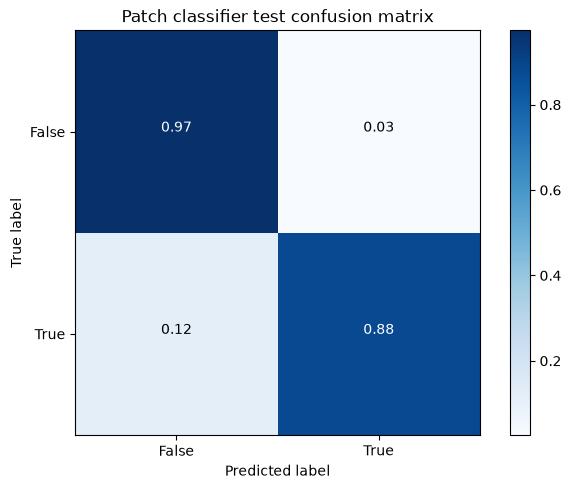

TPR/Recall:  0.878
FPR:  0.026
Accuracy:  0.926


In [30]:
# CELL REF: C2.4a

tpr = 0.       # calculate
fpr = 0.       # calculate
accuracy = 0.  # calculate
patch_clf_cm = np.zeros((2,2))  # calculate 
# YOUR CODE HERE
# Preprocess test images
X_test_processed = preprocess_images_patch_classifier(X_test_intensity)

# Predict probabilities
y_probs = patch_classifier.predict(X_test_processed, device=device)

# Convert probabilities into predicted labels
y_pred = (y_probs >= 0.5).astype(int)

# Calculate confusion matrix
patch_clf_cm = confusion_matrix(y_test, y_pred)

# Extract values
TN = patch_clf_cm[0, 0]
FP = patch_clf_cm[0, 1]
FN = patch_clf_cm[1, 0]
TP = patch_clf_cm[1, 1]

# Calculate performance metrics
tpr = TP / (TP + FN)
fpr = FP / (FP + TN)
accuracy = (TP + TN) / np.sum(patch_clf_cm)

plot_confusion_matrix(patch_clf_cm, normalize=True, title='Patch classifier test confusion matrix')
plt.show()

print('TPR/Recall: ', tpr)
print('FPR: ', fpr)
print('Accuracy: ', accuracy)

In [31]:
# CELL REF: C2.4b

assert isinstance(tpr, float)
assert isinstance(fpr, float)
assert isinstance(accuracy, float)
assert(tpr <= 1)
assert(tpr >= 0)
assert(fpr <= 1)
assert(fpr >= 0)
assert(accuracy <= 1)
assert(accuracy >= 0)

**Q2.4a**: When would you use the pre-trained classifier over the one you trained? Refer to the confusion matrices in your answer.

YOUR ANSWER HERE

## Part 3 - Detection

### Region Proposals

You now have a classifier capable of identifying pedestrians in image patches. However, in order to be able to *detect* pedestrians in an image, an additional step is required: the image patches that may contain pedestrians need to be extracted from the full image. This is referred to as localization, and the extracted image patches are called 'region proposals'.

In this practicum we will take a brute force approach to localization. You will create a set of proposal bounding boxes that will be used to divide an image into patches. These proposal boxes are slid over the image as shown in the video below, cropping the region they envelop at every step. In order for the classifier to be able to accurately identify pedestrians in the image, there needs to be a large enough set of proposal bounding boxes to capture the most common shapes, sizes, and locations of pedestrians in the image plane. In practice, many bounding boxes are needed to account for the variability in apparent object size due to perspective effects; for example, pedestrians farther from the camera appear smaller i.e. can be enveloped in patches consisting of fewer pixels. However, more proposal bounding boxes equates to longer computation times as the classifier needs to evaluate more region proposals.

<img width="100%" alt="Bounding box sliding over frame" src="media/proposal_box_example.gif">
</img>

There is hence a tradeoff in the selection of the proposal bounding boxes. In this section, you will need to choose a number of bounding boxes to use for pedestrian localization in a video from the test set. We will use the distributions of the height and width of the bounding boxes in the train set to inform this selection.

Now we will use the 2D bounding boxes to approximate the distribution of bounding boxes in the dataset. In the following cell, we load the dimensions of the annotated bounding boxes in the train set as `bbox_height_widths`. This should allow us to make a reasonable estimate of the distribution of the heights and widths of the bounding boxes in the test set/sequence.

In [32]:
# CELL REF: C3.0a

from load_data import load_bbox_data

bbox_2d_list = load_bbox_data(filename='2d_bbox_data.txt')
bbox_height_widths = bbox_2d_list[:, :2]

Run the next cell to plot a heatmap showing the joint distribution of the (train set) bounding box dimensions, and unnormalised marginal distributions of the dimensions.

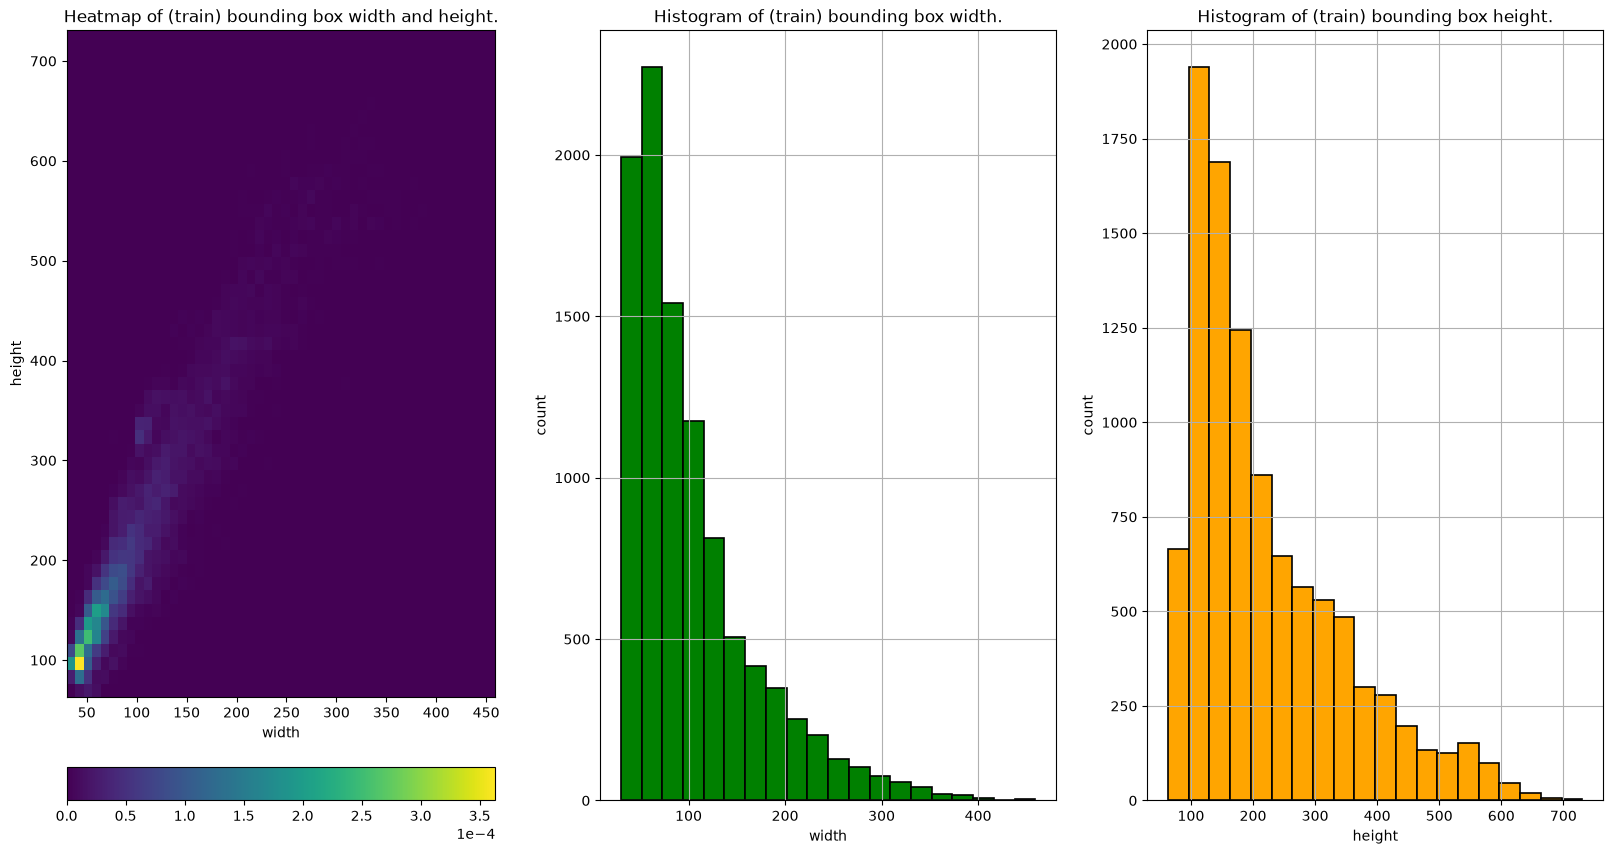

In [33]:
# CELL REF: C3.0b

from mpl_toolkits.axes_grid1 import make_axes_locatable

bbox_heights = bbox_height_widths[:, 0]
bbox_widths = bbox_height_widths[:, 1]
heatmap, xedges, yedges = np.histogram2d(bbox_widths, bbox_heights, bins=50, density=True)
extent = [xedges[0], xedges[-1], yedges[0], yedges[-1]]

fig = plt.figure(figsize=(20, 10))
heatmap_ax, width_ax, height_ax = fig.subplots(1,3)

im = heatmap_ax.imshow(heatmap.T, extent=extent, origin='lower')
divider = make_axes_locatable(heatmap_ax)
cax = divider.append_axes("bottom", size="5%", pad=0.7)
fig.colorbar(im, cax=cax, orientation='horizontal')
cax.ticklabel_format(style='sci', scilimits=(0,0))
heatmap_ax.set_title('Heatmap of (train) bounding box width and height.')
heatmap_ax.set_xlabel('width')
heatmap_ax.set_ylabel('height')


width_ax.hist(bbox_widths, bins=20, facecolor='green', edgecolor='black', linewidth=1.2)
width_ax.set_xlabel('width')
width_ax.set_ylabel('count')
width_ax.set_title('Histogram of (train) bounding box width.')
width_ax.grid(True)


height_ax.hist(bbox_heights, bins=20, facecolor='orange', edgecolor='black', linewidth=1.2)
height_ax.set_xlabel('height')
height_ax.set_ylabel('count')
height_ax.set_title('Histogram of (train) bounding box height.')
height_ax.grid(True)

plt.show()

## Exercise 3.1 - Region Proposals

Due to computational constraints, you will only use one proposal box size. Select this proposal box size based on the plots. 
<div class="alert alert-success">
Hint: ignore the low-density regions of the heatmap and histograms for best results on the test video, and take into account that the distribution has positive skew (a long tail on the right).
</div>

In [47]:
# CELL REF: C3.1a

# Select one proposal box size, based on the plots from the cell above.

proposal_bboxes = [(250, 150)]  # select h and w
# YOUR CODE HERE

assert np.all([[isinstance(dim, int) for dim in bbox] for bbox in proposal_bboxes]), 'non-integer dimensions'

proposal_bboxes = np.asarray(proposal_bboxes)
assert proposal_bboxes.shape == (1,2)
assert np.all(proposal_bboxes[:,1] < proposal_bboxes[:,0]), 'format not height, width'
assert np.all(proposal_bboxes > 0)

**Q3.1a**: Explain why you selected this proposal box size.

YOUR ANSWER HERE

**Q3.1b**: What is the trade-off in selecting the proposal box dimensions?

YOUR ANSWER HERE

Before generating the region proposals with your selected proposal box, we will load and visualize a snippet of one of the videos in the test set. We truncate the video to 49 frames to reduce the time spent on prediction.

In [48]:
# CELL REF: C3.1b

from vod.configuration import KittiLocations
from vod.frame import FrameDataLoader

kitti_locations = KittiLocations(root_dir=os.path.join(os.environ["DATA_DIR"], 'view_of_delft_PUBLIC'))

import cv2

seq_start_index = 1470
seq_end_index = 1519

sequence = []
for index in range(seq_start_index, seq_end_index):
    frame_data = FrameDataLoader(kitti_locations=kitti_locations, frame_number=str(index).zfill(5))
    sequence.append(frame_data.get_image())

In [49]:
# CELL REF: C3.1c

from mpiv_common.visualization import create_animation

anim = create_animation(sequence, interval_ms=100, figsize=(12, 6))
HTML(anim.to_html5_video())

The sequence contains a number of pedestrians, each at a different distance to the camera. There are people on bikes and scooters in the distance as well. These factors make this a more challenging task than classifying carefully selected patches (like in the previous section)!

Run the cell below to generate the region proposals with your proposal box, and note the number of proposal regions you obtain for each frame; it is likely quite large. 

The succeeding cell preprocesses the patches for prediction.

<div class="alert alert-info">
Note: to save time, <code>generate_sequence_proposals</code> only applies the sliding window over the bottom half of the image, so the number of proposals you would generate without this trick would be roughly double the number shown. 
</div>

In [50]:
# CELL REF: C3.1d

from image_processing import generate_sequence_proposals

sequence_proposals = generate_sequence_proposals(sequence, proposal_bboxes)
print(f'Number of region proposals per frame: {sequence_proposals.shape[1]}')

Number of region proposals per frame: 530


**Q3.1c**: We only pass the sliding window over the bottom half of the image to save time. Why do we slide it over  the bottom half, and e.g. not the top half, of the image?

That's where the floor is.

#### Pedestrian detection

As mentioned in Section 2, we will use the pre-trained model loaded earlier in the practicum to classify the region proposals.

You may want to grab a coffee after starting the cell that runs the classifier on the region proposals. The model needs to classify hundreds or even thousands of patches for each frame (the exact number depends on your chosen proposal box size), and without specialised hardware this is very time-consuming...

In [51]:
# CELL REF: C3.1e

from preprocessing_fns import preprocessing_fn_mobilenet

print('Running model on region proposals. This will take a while!')
for frame in tqdm(sequence_proposals):
    frame_patches = np.concatenate([preprocessing_fn_mobilenet(proposal_patch.image) for proposal_patch in frame], 0)
    predictions = patch_classifier.predict(frame_patches)
    
    for i, pred in enumerate(predictions):
        frame[i].score = pred


Running model on region proposals. This will take a while!


  0%|          | 0/49 [00:00<?, ?it/s]

We need to threshold the predictions to identify regions that are likely to contain pedestrians. However, it is possible that multiple region proposals for the same pedestrian are classified positively after thresholding due to the overlap of these region proposals. To reduce overlapping proposals to a single one, we take the one with the most confident prediction and discard the rest. We will use [Non-Maximum Suppression](https://towardsdatascience.com/non-maximum-suppression-nms-93ce178e177c) (NMS) to achieve this. This algorithm discards less probable predictions that have at least a given amount of overlap with a more confident prediction.

![SegmentLocal](media/overlapping_bboxes.png "Overlapping bounding boxes")

NMS uses the Intersection-over-Union (IoU) metric to quantify the amount of overlap between two bounding boxes. This metric is the ratio of the area of overlap and the area of the union of the bounding boxes and therefore has a range of $[0,1]$. A simple NMS algorithm evaluates each of the bounding boxes in the set of positive predictions pair-wise using the IoU, discarding bounding boxes that exceed some threshold IoU value. Since the highest-confidence bounding boxes are evaluated first, only the most likely region proposals remain after the application of NMS (hence the name **Non-Maximum** Supression).

![SegmentLocal](media/iou_equation.png "IoU")
<p style="text-align: center;"><center>
    <sub>
        Image taken from 
        <a href="https://www.pyimagesearch.com/2016/11/07/intersection-over-union-iou-for-object-detection/">
            https://www.pyimagesearch.com/2016/11/07/intersection-over-union-iou-for-object-detection/</a> 
         on 3 September 2021. 
    </sub>
</center></p>

Run the next two cells to threshold the predictions and apply NMS to the remaining positively-classified regions. We will use an IoU threshold of 0. (i.e. no overlap between bounding boxes allowed) for the NMS step for simplicity.

In [52]:
# CELL REF: C3.1f

discrimination_threshold = .995    # confidence threshold for classifier predictions
pedestrian_patches = [[proposal_patch for proposal_patch in frame if proposal_patch.score >= discrimination_threshold] for frame in tqdm(sequence_proposals)]

  0%|          | 0/49 [00:00<?, ?it/s]

In [53]:
# CELL REF: C3.1g

import torch
from torchvision.ops import nms

nms_patches = []
overlap_thresh = 0.    # overlap threshold for NMS algorithm
for frame in pedestrian_patches:
    all_bboxes = np.asarray([patch.bbox.get_bbox_corners() for patch in frame])
    confidences = np.asarray([patch.score for patch in frame])
    if len(all_bboxes) > 0:
        boxes = torch.tensor(all_bboxes, dtype=torch.float32)
        scores = torch.tensor(confidences, dtype=torch.float32)
        idx = nms(boxes, scores, overlap_thresh).cpu().numpy()
        nms_patches.append([frame[i] for i in idx])
    else:
        nms_patches.append([])


We can now visualize the remaining predictions on the video snippet.

In [54]:
# CELL REF: C3.1h

# The bounding boxes per frame. create_animation draws them on each frame of `sequence`,
# so no annotated copy of the whole sequence is kept in memory.
detection_bboxes = [[patch.bbox for patch in frame_patches] for frame_patches in nms_patches]
color_detection = (0, 255, 0)  # green

In [55]:
# CELL REF: C3.1i

anim = create_animation(sequence, interval_ms=100, bbox_sets=[(detection_bboxes, color_detection)], figsize=(12, 6))
HTML(anim.to_html5_video())

**Q3.1d**: Can you explain why the predicted bounding boxes are not centered on - and do not fit tightly around - the pedestrians in the video? How could the problems you identified be mitigated?

YOUR ANSWER HERE

## Part 4 - 3D Location Priors

It is possible to create a smaller set of (more probable) region proposals if additional information is available. For example, other sensors may 'detect' the presence of an object in the space around the vehicle. These detections can be used as a prior on the location of objects. We will refer to this region proposal method as the 'smart' method from here on out, to distinguish it from the previous 'sliding window' approach.

In order to use the 3D priors, we need to be able to project points in the world coordinate system ('world space') to the image plane. You will need to write code performing the required transformations. We first load a frame from the test sequence, and the corresponding 3D and pre-projected 2D bounding boxes that you can use to verify that  your projection is correct.

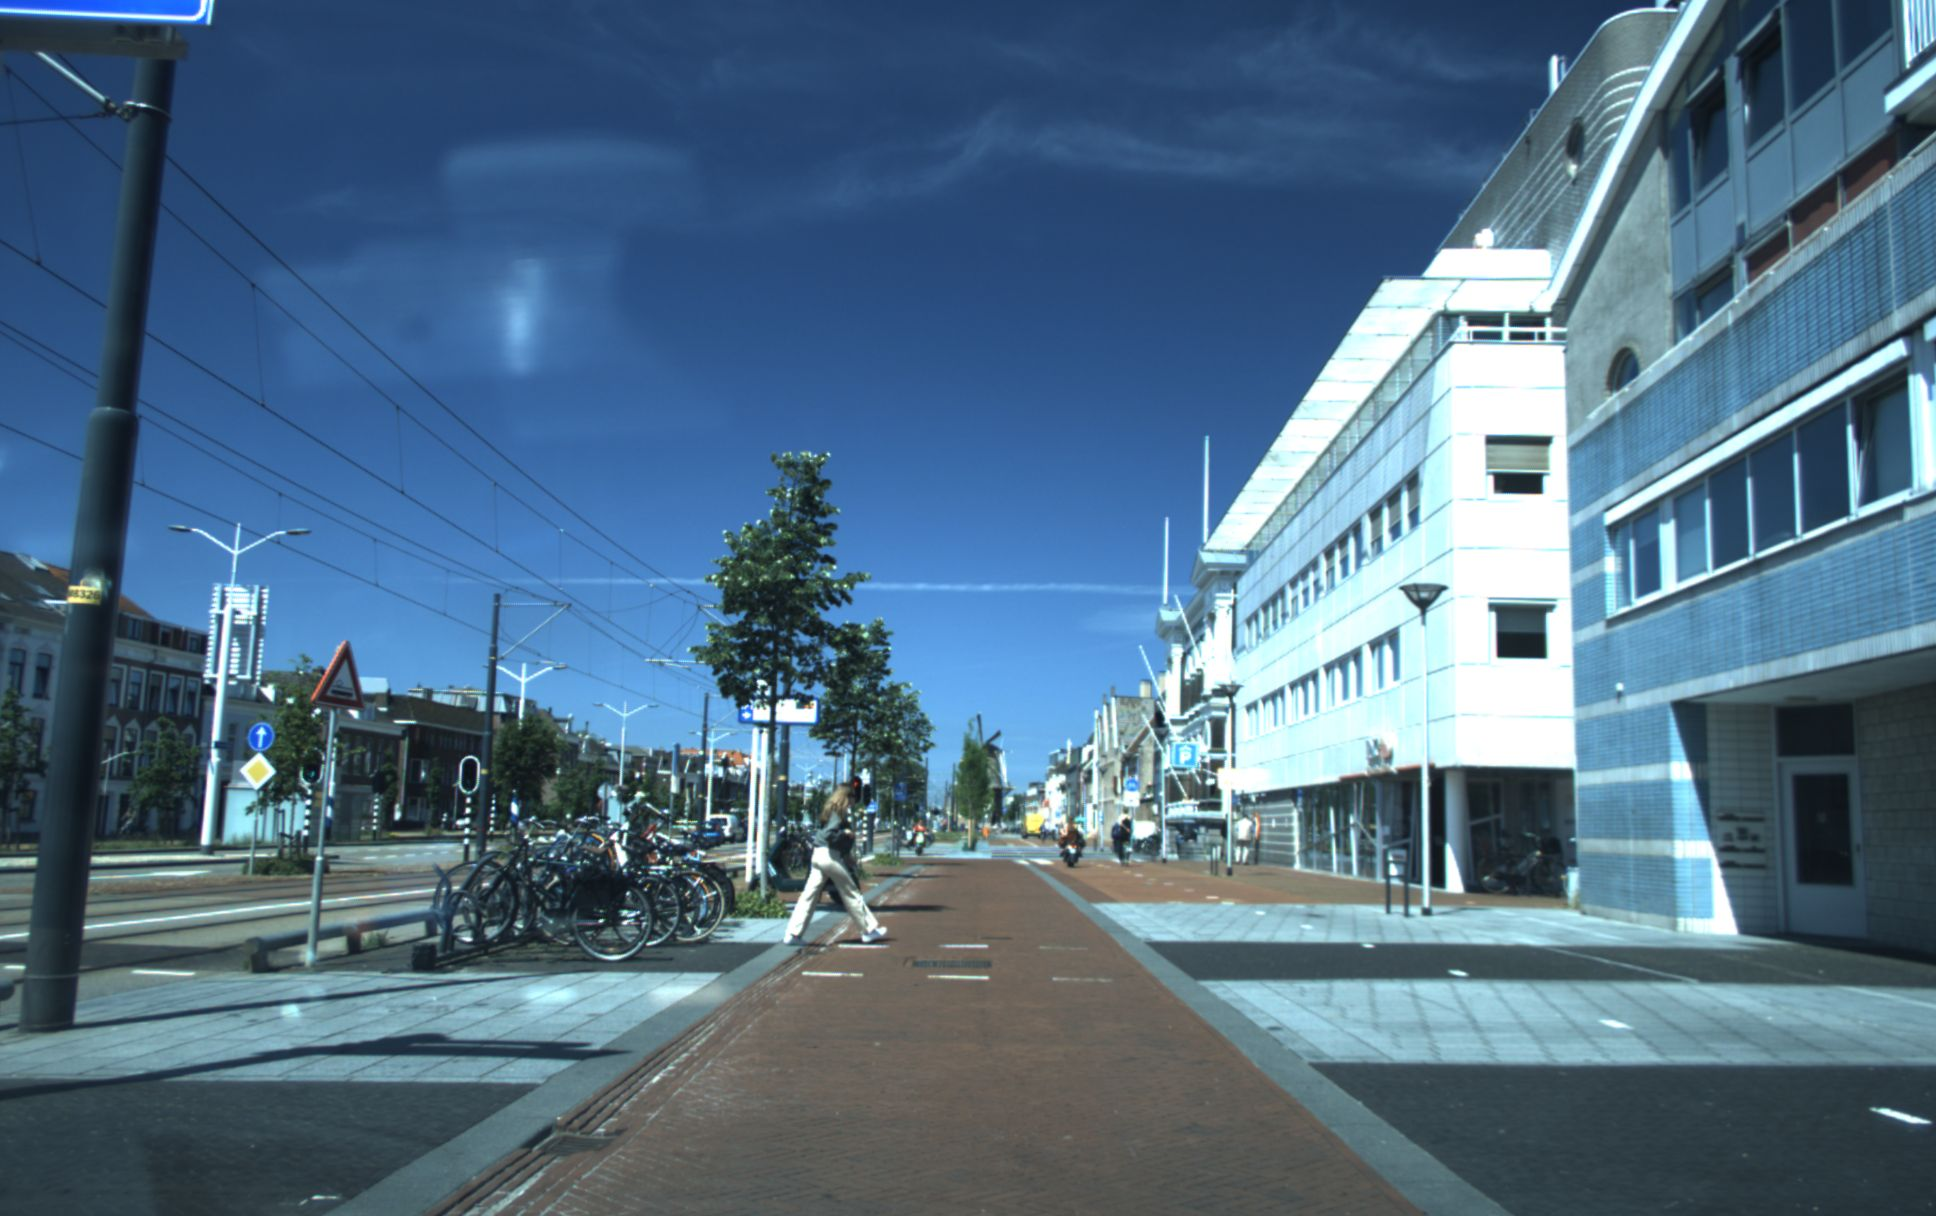

In [43]:
# CELL REF: C4.0a

from visualization import showimage

example_frame_index = 1490
example_measurements = FrameDataLoader(kitti_locations=kitti_locations, frame_number=str(example_frame_index).zfill(5))
example_image = example_measurements.get_image()

showimage(example_image)

In [44]:
# CELL REF: C4.0b

from BoundingBox import BoundingBox

from sequence_loader import labels_raw_to_dict

example_labels = labels_raw_to_dict(example_measurements.raw_labels)
labels_2d = [example_labels['2d_bbox'] for example_labels in example_labels if example_labels['label_class'] == "Pedestrian"] 

bbox_labels = []
for label in labels_2d:
    bbox = BoundingBox(label['y1'], label['x1'], label['y2'], label['x2'], from_corners=True)
    bbox_labels.append(bbox)

## Exercise 4.1 - 3D-to-2D Projection

The given function `create_3d_bbox` returns the corners of the 3D bounding box in the object frame, in homogeneous coordinates (shape `(8, 4)`). It uses the length (`l`; along x-axis), width (`w`; along y-axis), and height (`h`; along z-axis). Project the corners to the camera frame using the *coordinates of the centre of the bottom face in the camera frame* (`x_cam`, `y_cam`, `z_cam`) and the *orientation in the LiDAR frame* (`yaw_lidar_rad`; rotation about z-axis, `0` if aligned with the x-axis) of the 3D bounding box. Use the camera calibration matrix `P2` to project these (camera) coordinates to the image plane. Use homogeneous coordinates where relevant.

![SegmentLocal](media/coord_systems_diagram.svg "Coordinate system relations")

<div class="alert alert-info">
Note: the camera and LiDAR frame are not aligned in the dataset that we are using. This is not shown in the figure.
</div>

In [45]:
# CELL REF: C4.1a

from create_3d_bbox import create_3d_bbox


def get_T_cam_object(label_dict, T_cam_lidar):
    # Coordinates of the centre of the bottom face of the 3D bounding box in the camera frame 
    x_cam, y_cam, z_cam = label_dict['bottom_center_cam']
    
    # Dimensions of bounding box in object frame
    # i.e. l is aligned with the x-axis, w with the y-axis, and h with the z-axis
    l, w, h = label_dict["extent_object"]
    
    # Rotation of the bounding box about the LiDAR z-axis, where 0 is aligned with the x-axis.
    # The rotation is defined in a right-handed coordinate system, so counter-clockwise is positive.
    # It is important to note that the rotation is defined in the LiDAR frame, which has the z-axis,
    # not the y-axis (as in the camera frame), facing up (towards the sky).
    # Hence your rotation matrix should be defined for rotation about the z-axis!
    yaw_lidar_rad = label_dict['yaw_lidar_rad']
    
    R_lidar_object = None   # define rotation in LiDAR frame
    # YOUR CODE HERE
    raise NotImplementedError()
    
    assert R_lidar_object.shape == (3, 3)
    
    # Convert rotation in LiDAR frame to camera frame - you can ignore this.
    # If you are struggling to get the correct result, check whether you have defined
    # your rotation matrix in the LiDAR frame (not the camera frame).
    R_cam_lidar = T_cam_lidar[:3, :3]
    R_cam_object = R_cam_lidar.dot(R_lidar_object)
    
    assert R_cam_object.shape == (3, 3)
    
    T_cam_object = None   # define transform from object to camera frame
    # YOUR CODE HERE
    raise NotImplementedError()
    assert T_cam_object.shape == (4, 4)
    assert T_cam_object.dtype == np.float32  # float32 to avoid k3d coercion warnings
    
    return T_cam_object
    
    
def corners_object_to_cam(corners_object, T_cam_object):
    corners_cam = None   # calculate bounding box corners in camera frame
    # YOUR CODE HERE
    raise NotImplementedError()
    assert corners_cam.shape == (8, 4)
    
    return corners_cam
    
    
def project_points(projection_matrix, points):
    """
    projection_matrix: The projection matrix based on the intrinsic camera calibration.
    points: Nx[x,y,z,1.0] np.array of the points that need to be projected to the camera image.
    return: Nx[u,v] rounded coordinates of the points in the camera image as int data type.
    """
    assert points.shape[-1] == 4
    uvs = None   # calculate points in image plane
    # YOUR CODE HERE
    raise NotImplementedError()

    
    return uvs


def project_label(label_dict, P2, T_cam_lidar):
    corners_object = create_3d_bbox(label_dict["extent_object"])
    assert corners_object.shape == (8, 4), 'hint: use homogeneous coordinates'
    assert corners_object.dtype == np.float32
    
    T_cam_object = get_T_cam_object(label_dict, T_cam_lidar)
    
    corners_cam = corners_object_to_cam(corners_object, T_cam_object)
    corners_img = project_points(P2, corners_cam)
    assert corners_cam.shape == (8, 4)
    assert corners_img.shape == (8, 2)
    
    return corners_img


def get_bbox_from_corners(corners):
    min_coords = list(map(int, np.min(corners, axis=0)))
    max_coords = list(map(int, np.max(corners, axis=0)))
    bbox = BoundingBox(min_coords[1], min_coords[0], max_coords[1], max_coords[0], from_corners=True)
    return bbox


def label3D_to_label2D(label3d, P2, T_cam_lidar):
    corners_img = project_label(label3d, P2, T_cam_lidar)
    assert corners_img.shape == (8, 2)
    bbox_img = get_bbox_from_corners(corners_img)
    
    return bbox_img

In [46]:
# CELL REF: C4.1b

from vod.frame import FrameTransformMatrix

frame_transform_matrix = FrameTransformMatrix(example_measurements)

camera_projection_matrix = frame_transform_matrix.camera_projection_matrix

T_cam_lidar = frame_transform_matrix.t_camera_lidar

bbox_labels2d = []
bbox_corners_cam = []
for label3d in example_labels:
    if label3d['label_class'] == 'Pedestrian':
        label2d = label3D_to_label2D(label3d, camera_projection_matrix, T_cam_lidar)
        bbox_labels2d.append(label2d)

NotImplementedError: 

In [ ]:
# CELL REF: C4.1c

# Ensure that the assertion in this cell passes before continuing!

label_dict = {
    'bottom_center_cam': [10, 22, 8],
    'extent_object': [1.2, 0.6, 0.3],
    'yaw_lidar_rad': 1.2, 
}

assertion_answer = [
    [-9.3479478e-01, -3.5486701e-01,  1.5104900e-02,  1.0000000e+01],
    [ 2.8077411e-02, -1.1622145e-01, -9.9282640e-01,  2.2000000e+01],
    [ 3.5407686e-01, -9.2766488e-01,  1.1860690e-01,  8.0000000e+00],
    [ 0.0000000e+00,  0.0000000e+00,  0.0000000e+00,  1.0000000e+00],
]

assert np.allclose(get_T_cam_object(label_dict, T_cam_lidar), assertion_answer), 'Your implementation up to and including \'get_T_cam_object()\' is incorrect. Check your code and the theory and try again!'

The cell below plots the annotated objects in the camera frame using `k3d`. This plot uses the vod devkit, not your code. You can change the viewpoint interactively by moving the mouse. If you additionally hold the shift-key (or alternatively use the right button of the mouse), you can move the focus point of the camera. By scrolling with the mouse, you can zoom in and out. Take a look at the [k3d](https://www.k3d-jupyter.org/) docs for more information. You will use `k3d` in later practica as well. 

The bounding boxes are shown in the camera frame, each class having a different colour: <span style="color:#00FF00">Pedestrian</span>, <span style="color:#0000FF">Cyclist and bicycle</span>, <span style="color:#FF0000">rider</span>, and <span style="color:#AAAAAA">other classes</span> (bicycle racks, scooters and a motorcycle in this frame).

Compare the plot with the camera image. Then check whether your projections align with the annotations in the image plane.

<div class="alert alert-info">
Note: If you run into an import error in the following cell, check that you do not have all-uppercase variables defined in the global scope of your notebook.
</div>

In [ ]:
# CELL REF: C4.1d

import k3d
from vod.visualization import Visualization3D
from vod.visualization.settings import label_color_palette_3d, label_line_width_3d

label_color_palette_3d["motor"] = 0xAAAAAA # motor class label does not exist in vod devkit, while it exists in the dataset
label_line_width_3d["motor"] = 0.02

visualization = Visualization3D(example_measurements)

visualization.draw_plot(annotations_plot=True)
visualization.plot.camera = [1.0, -4.5, -5.0, 1.0, -1.0, 0.0, 0.0, 0.0, 1.0]

# save plot to disk
with open('C4.1d.html', 'w') as f:
    f.write(visualization.plot.get_snapshot())

# Here's the image again, for comparison
example_image = example_measurements.image
showimage(example_image)

Let's now verify that the projected bounding box matches the annotated 2D one, by drawing them both to the image frame.

In [ ]:
# CELL REF: C4.1e

from visualization import draw_bbox_to_image

example_image_copy = copy(example_image)
# Draw GT bbox in red
for bbox in bbox_labels:
    draw_bbox_to_image(example_image_copy, bbox, color=(255,0,0))
    
# Draw projected bbox in green
for bbox in bbox_labels2d:
    draw_bbox_to_image(example_image_copy, bbox)

In [ ]:
# CELL REF: C4.1f

print('Projected (green) and annotated (red) bounding boxes')
showimage(example_image_copy)

A small mismatch error can be expected (e.g. from numerical/rounding errors) - just make sure that the assertion in the cell below passes.

In [ ]:
# CELL REF: C4.1g

annotated_bbox = bbox_labels[0]
projected_bbox = bbox_labels2d[0]

assert np.allclose(annotated_bbox.get_bbox_corners(), projected_bbox.get_bbox_corners(), atol=10)

If the bounding boxes do not (roughly) overlap, you will need to check your projection code before proceeding.

---

Now imagine that we have a 3D prior for the location of each pedestrian in the video. We can construct 3D bounding boxes  at this location and project these to 2D region proposals. This allows us to only propose regions that are likely to contain a pedestrian instead of tiling the entire image with proposals.

We will simulate the 3D priors by offsetting the (annotated) coordinates of the bottom centre of pedestrians' 3D bounding boxes with a very small amount of Gaussian noise. To stay within the scope of this practicum, we will assume that the 3D bounding box orientation and dimensions are known. These bounding boxes will be projected to the image plane using your code to generate region proposals for the classifier.

Note that we are no longer filtering the labels to include only pedestrians like we did in the example above. This is more realistic as the sensors typically used in a vehicle may be unable to distinguish between detected objects.

In [ ]:
# CELL REF: C4.1h

from ImagePatch import ImagePatch
from BoundingBox import clip_bbox_to_image
from sequence_loader import labels_raw_to_dict


sequence_proposals2d = []
for index in range(seq_start_index, seq_end_index):
    measurement = FrameDataLoader(kitti_locations=kitti_locations, frame_number=str(index).zfill(5))
    frame_labels3d = labels_raw_to_dict(measurement.raw_labels)
    frame_image = measurement.get_image()
    frame_proposals = []
    frame_transform_matrix = FrameTransformMatrix(measurement)
    camera_projection_matrix = frame_transform_matrix.camera_projection_matrix
    for label3d in frame_labels3d:
        # Create 'good' proposal
        # Corrupt label by offsetting bottom centre with a small amount of noise
        label3d['bottom_center_cam'] += np.random.normal(loc=0., scale=1e-2, size=(3,))        
        # Project label to 2D
        label2d = label3D_to_label2D(label3d, camera_projection_matrix, T_cam_lidar)
        clip_bbox_to_image(label2d, frame_image.shape[:2])
        patch_image = frame_image[label2d.v:label2d.v+label2d.h, label2d.u:label2d.u+label2d.w]
        patch = ImagePatch(patch_image, label2d)
        frame_proposals.append(patch)

    sequence_proposals2d.append(frame_proposals)

To get an idea of the region proposals this method produces, we will plot the proposals for an example frame.

In [ ]:
# CELL REF: C4.1i

proposal_index = example_frame_index - seq_start_index
frame_proposals = sequence_proposals2d[proposal_index]

example_image_copy = copy(example_image)

# Draw proposal bbox in blue
for proposal in frame_proposals:
    bbox = proposal.bbox
    draw_bbox_to_image(example_image_copy, bbox, color=(0,0,255))

In [ ]:
# CELL REF: C4.1j

print('Region proposals produced by \'smart\' method, shown in blue.')
showimage(example_image_copy)

Now apply the classifier to these proposals!

In [ ]:
# CELL REF: C4.1k

from mpiv_common.visualization import showimage

example_measurements = FrameDataLoader(kitti_locations=kitti_locations, frame_number=str(example_frame_index).zfill(5))
example_image = example_measurements.image

print('Running model on region proposals. This may take a while.')
for frame in tqdm(sequence_proposals2d):
    frame_patches = np.concatenate([preprocessing_fn_mobilenet(proposal_patch.image) for proposal_patch in frame], 0)
    predictions = patch_classifier.predict(frame_patches)
    
    for i, pred in enumerate(predictions):
        frame[i].score = pred

In [ ]:
# CELL REF: C4.1l

threshold = 0.9
pedestrian_patches2d = [[proposal_patch for proposal_patch in frame if proposal_patch.score >= threshold] for frame in sequence_proposals2d]

In [ ]:
# CELL REF: C4.1m

nms_patches2d = []
for frame in pedestrian_patches2d:
    all_bboxes = np.asarray([patch.bbox.get_bbox_corners() for patch in frame])
    confidences = np.asarray([patch.score for patch in frame])
    if len(all_bboxes) > 0:
        boxes = torch.tensor(all_bboxes, dtype=torch.float32)
        scores = torch.tensor(confidences, dtype=torch.float32)
        idx = nms(boxes, scores, overlap_thresh).cpu().numpy()
        nms_patches2d.append([frame[i] for i in idx])
    else:
        nms_patches2d.append([])


In [ ]:
# CELL REF: C4.1n

detection_bboxes2d = [[patch.bbox for patch in frame_patches] for frame_patches in nms_patches2d]

In [ ]:
# CELL REF: C4.1p

anim = create_animation(sequence, interval_ms=100, bbox_sets=[(detection_bboxes2d, color_detection)], figsize=(12, 6))
HTML(anim.to_html5_video())

These bounding boxes (should) look much better than when you used the sliding window to generate region proposals.

## Part 5 - Evaluation

### Detection evaluation metrics

We can now evaluate the object detector for both region proposal schemes. This will be done qualitatively, or visually, and quantitatively.

The detector can be qualitatively assessed by visually comparing the model's detections with the ground truth bounding boxes in the image.

To quantitatively evaluate the performance of the model, we will use the [mean Average Precision](https://towardsdatascience.com/map-mean-average-precision-might-confuse-you-5956f1bfa9e2) (mAP) metric. This metric is widely used to assess object detectors e.g. in the well-known [Pascal VOC](http://host.robots.ox.ac.uk/pascal/VOC/) and [COCO](https://cocodataset.org/#home) object detection challenges.

You will need a new metric to be able to calculate the AP (and mAP, more on the difference later), the 'Precision'. The Precision is the ratio of True Positives (TP) to the total number of predicted positives (TP + FP). 

$\text{Precision} = \frac{TP}{TP + FP}$

The other (hopefully familiar) metric used in the calculation is the True Positive Rate (TPR), often called 'Recall' in the context of object detection. As a reminder:

$TPR = \text{Recall} = \frac{TP}{TP + FN}$

As you have seen earlier in the practicum, the value of these metrics depends on the threshold on the classifier's 'confidence' score used to divide predictions into 'positive' and 'negative' samples. In object detection we also want to evaluate how well our predicted bounding boxes align with the true location of the object. We can use the IoU to quantify the goodness of fit between the predicted and true bounding boxes, and will threshold this metric to calculate the Precision and Recall of our detection model for a given classifier threshold.

The Average Precision for a particular IoU threshold is found by calculating the area under the Precision-Recall curve i.e. the Precision and Recall values for a range of classification thresholds. The mean Average Precision is then the mean of the Average Precision over a range of IoU thresholds.

### Evaluating the detector with the 'sliding window' region proposal method

You will start by evaluating the object detector that used your proposed sliding window to generate region proposals.

#### Ground truth location

First, we need to know what the true location of the pedestrians in our sequence is. We can use the human-annotated ('ground truth') bounding boxes that are available for evaluation as an estimate of this true location. The cells below load these labels in and show them in red in the video with the model's predicted bounding boxes. Keep in mind that we are displaying the predictions for a single pre-selected classifier threshold, but will evaluate the object detection model for a range of thresholds.

In [ ]:
# CELL REF: C5.0a

from BoundingBox import BoundingBox

pedestrian_gt_bboxes = []  # One list of ground truth BoundingBox objects per frame.
for index in range(seq_start_index, seq_end_index):
    measurement = FrameDataLoader(kitti_locations=kitti_locations, frame_number=str(index).zfill(5))
    frame_labels3d = labels_raw_to_dict(measurement.raw_labels)
    frame_gt_bboxes = []
    for annotation in frame_labels3d:
        if annotation["label_class"] == "Pedestrian":
            v1 = annotation["2d_bbox"]['y1']
            v2 = annotation["2d_bbox"]['y2']
            u1 = annotation["2d_bbox"]['x1']
            u2 = annotation["2d_bbox"]['x2']
            frame_gt_bboxes.append(BoundingBox(v1, u1, v2, u2, from_corners=True))
    pedestrian_gt_bboxes.append(frame_gt_bboxes)
color_gt = (255, 0, 0)  # red

In [ ]:
# CELL REF: C5.0b

anim = create_animation(
    sequence,
    interval_ms=100,
    bbox_sets=[(detection_bboxes, color_detection), (pedestrian_gt_bboxes, color_gt)],
    figsize=(12, 6),
)
HTML(anim.to_html5_video())

Now we must match each of the ground truth bounding boxes with a predicted bounding box. Each prediction can only be matched to one ground truth box, and vice versa. We use the IoU to find the best matches. Note that some of the ground truth boxes may not overlap with any of the predictions (IoU of 0), in which case no prediction is assigned to that ground truth. Hence these boxes are classed as False Negatives regardless of the IoU threshold.

<div class="alert alert-info">
Note: the details of the matching algorithm are beyond the scope of the course.
</div>

In [ ]:
# CELL REF: C5.0c

from evaluation import generate_metrics_dict

gt_bboxes = []
for index in range(seq_start_index, seq_end_index):
    measurement = FrameDataLoader(kitti_locations=kitti_locations, frame_number=str(index).zfill(5))
    frame_labels3d = labels_raw_to_dict(measurement.raw_labels)
    bboxes_per_frame = []
    for annotation in frame_labels3d:
        bbox_dict = annotation["2d_bbox"]

        v1 = annotation["2d_bbox"]['y1']
        v2 = annotation["2d_bbox"]['y2']
        u1 = annotation["2d_bbox"]['x1']
        u2 = annotation["2d_bbox"]['x2']
        BoundingBox(v1, u1, v2, u2, from_corners=True)

        if annotation['label_class'] == "Pedestrian":
            bboxes_per_frame.append(BoundingBox(v1, u1, v2, u2, from_corners=True).get_bbox_corners())
    gt_bboxes.append(bboxes_per_frame)

discrimination_thresholds = np.linspace(0., 1., 101)
iou_thresholds = [0.5, 0.55, 0.6, 0.65, 0.7, 0.75, 0.8, 0.85, 0.9, 0.95] # we use the COCO thresholds

metrics_dict = generate_metrics_dict(sequence_proposals, gt_bboxes, discrimination_thresholds, iou_thresholds)

#### Precision-Recall curve

Let's plot the Precision-Recall curve for the range of IoU thresholds.

In [ ]:
# CELL REF: C5.0d

from evaluation import plot_pr_curve

iou_thresh = 0.5
plot_pr_curve(metrics_dict, iou_thresh)

**Q5.0a**: Why is there a trade-off between Precision and Recall?

YOUR ANSWER HERE

#### Mean Average Precision (mAP)

By averaging the AP over the IoU thresholds, we can obtain the mAP.

In [ ]:
# CELL REF: C5.0e

from metrics import mAP

mAP_value = mAP(metrics_dict)
print(f'Mean Average Precision: {mAP_value*100:.01f}')

This value of mAP is very low compared to state-of-the-art detectors. For reference, the Co-DETR detector reports an mAP of 66.0 on the COCO test-dev set ([Zong et al., 2023](https://arxiv.org/abs/2211.12860)).

**Q5.0b**: What can you infer about the relative strengths and weaknesses of the model from the value of the mAP on the test sequence and the values of the classification metrics on the classification test set?

YOUR ANSWER HERE

### Evaluating the detector with 'smart' region proposals

We can repeat the previous steps for the second region proposal method, and compare the performance of the detector between the proposal generation methods.

As stated in the introduction to Part 5, we will also do a qualitative check for the smart region proposals. We will simply plot the proposals and the Ground Truth bounding boxes for this step.

In [ ]:
# CELL REF: C5.0f

# The ground truth boxes are the same as for the sliding window proposals (`pedestrian_gt_bboxes`, C5.0a).
bbox_sets_smart = [(detection_bboxes2d, color_detection), (pedestrian_gt_bboxes, color_gt)]

In [ ]:
# CELL REF: C5.0g

anim = create_animation(
    sequence,
    interval_ms=100,
    bbox_sets=bbox_sets_smart,
    figsize=(12, 6),
)
HTML(anim.to_html5_video())

#### Precision-Recall curves

Next, we compare the PR curves of this region proposal method with the 'sliding window' approach.

In [ ]:
# CELL REF: C5.0h

metrics_dict2d = generate_metrics_dict(sequence_proposals2d, gt_bboxes, discrimination_thresholds, iou_thresholds)

In [ ]:
# CELL REF: C5.0i

from evaluation import plot_pr_curves

iou_thresh = 0.5
plot_pr_curves({'sliding window': metrics_dict, 'smart': metrics_dict2d}, iou_thresh)

**Q5.0c**: Which method is better at localization? How can you tell from the plots?

YOUR ANSWER HERE

#### Mean Average Precision (mAP)

Calculate the mAP of the 'smart' proposal method using the cell below.

In [ ]:
# CELL REF: C5.0j

mAP_2d = mAP(metrics_dict2d)
print(f'Mean Average Precision: {mAP_2d*100:.01f}')

**Q5.0d**: What are the benefits of the 'smart' proposal method over the 'sliding window' method?

YOUR ANSWER HERE

## Conclusion

In this practicum you have:
- learnt the distinction between features and classifiers
- produced hand-crafted and learnt feature representations
- observed that neural network classifiers can outperform classical models
- seen that object detection consists of two tasks: localisation and classification
- generated region proposals with a sliding window (the naive approach)
- projected 3D points in world space to the 2D image plane
- improved the efficiency and performance of an object detector by using (simulated) 3D priors for the region proposals